In [1]:
from maite_datasets.object_detection import SeaDrone

# Downloads to ./data/seadrone on first run (~1.2 GB for the validation split).
seadrone = SeaDrone(root="./data", image_set="val", download=True)
print(f"{len(seadrone)} images")

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1547 images


In [2]:
from dataeval_flow import run_task
from dataeval_flow.config import (
    DatasetProtocolConfig,
    PipelineConfig,
    SourceConfig,
    TaskConfig,
    ViewConfig,
    ViewOperation,
)
from dataeval_flow.workflows.triage import TriageConfig

triage_workflow = TriageConfig(
    name="triage",
    checks={"factor-issues": {"max_examples": 6}},  # distinct values shown per column in the report
)

task = TaskConfig(
    name="triage_seadrone",
    workflow="triage",
    sources="seadrone_val",
)

config = PipelineConfig(
    max_processes=2,
    datasets=[DatasetProtocolConfig(name="seadrone", dataset=seadrone)],
    views=[
        ViewConfig(
            name="sample",
            operations=[
                ViewOperation(type="Shuffle", params={"seed": 0}),
                ViewOperation(type="Limit", params={"size": 200}),
            ],
        )
    ],
    sources=[SourceConfig(name="seadrone_val", dataset="seadrone", view="sample")],
    workflows=[triage_workflow],
    tasks=[task],
)

In [3]:
result = run_task(config, task)
print(f"success={result.success}  health={result.health['status']}")

/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_binning.py:418: UserWarning: `date_time` was dropped: nearly every row holds a different value, so the column identifies rows rather than grouping them, and it is not numeric so there is no order along which to cut it into groups. Map the values onto a smaller vocabulary to keep the factor. See Metadata.dropped_factors.
  factor_info = metadata.factor_info
/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_binning.py:418: UserWarning: `altitude`, `compass_heading`, `frame`, `gimbal_heading`, `gimbal_pitch`, `object_id`, `object_size`, `speed`, `xspeed` and `yspeed` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"altitude": [...]} to control this.
  factor_info = metadata.factor_info
/builds/jatic/aria/dataeval-flow/src/dataeval_flo

success=True  health=warning


In [4]:
print(result.report())


  TRIAGE
  Workflow:  triage
  Timestamp: 2026-11-14T08:48:04.650129+00:00
  Duration:  11.61s
  Source:    seadrone_val (seadrone[sample])

  Steps: 2 ran

  SUMMARY
  Unreadable factors ......................................... 3 factors  [!!]
  Columns dominated by one value ............................. 5 factors  [..]
  Degenerate factors ......................................... 1 factors  [..]
  Unpinned continuous bins .................................. 10 factors  [..]
  Unpinned categorical vocabularies .......................... 5 factors  [..]
  Suggested policy .............. add to configuration under `metadata:`  [..]
  Verified ................................................. 5 recovered  [..]
  Recommended policy ............ pins 17 factors as read from this data  [..]

  Health: 1 warning(s) [!!] — review flagged findings

  UNREADABLE FACTORS                                                   3 factors
  date_time — [blocking] cardinality_over_budget @ unit
    200

In [5]:
# The page styles its whole document, so the docs show it in an iframe of its own.
import html

from IPython.display import display


def show(page: str, height: int = 560) -> None:
    """*page* in an iframe, so its stylesheet and script stay inside it."""
    frame = (
        f'<iframe srcdoc="{html.escape(page, quote=True)}" title="HTML report" loading="lazy" '
        f'style="width:100%;height:{height}px;border:1px solid #d1d9e0;border-radius:6px"></iframe>'
    )
    display({"text/html": frame}, raw=True)

<iframe srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Triage</title>
<style>:root { color-scheme: light dark;
 --bg: #ffffff; --card: #ffffff; --soft: #f6f8fa; --ink: #111827; --muted: #6b7280; --rule: #e5e7eb;
 --link: #1d4ed8; --ok: #16a34a; --info: #2563eb; --warning: #d97706; --mark: #dc2626;
 --s0: #2563eb; --s1: #d97706; --s2: #7c3aed; --s3: #16a34a;
 --tag: #eef2ff; --tag-ink: #1e1b4b;
}
@media (prefers-color-scheme: dark) { :root {
 --bg: #0f1115; --card: #171a21; --soft: #1d212a; --ink: #e5e7eb; --muted: #9ca3af; --rule: #2a2f3a;
 --link: #93c5fd; --ok: #22c55e; --info: #60a5fa; --warning: #f59e0b; --mark: #f87171;
 --s0: #60a5fa; --s1: #f59e0b; --s2: #a78bfa; --s3: #22c55e;
 --tag: #232a3d; --tag-ink: #c7d2fe;
} }
body { margin: 0; color: var(--ink); background: var(--bg);
 font: 15px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif; }
main { max-width: 72rem; margin: 0 auto; padding: 1.5rem; }
a { color: var(--link); }
h1, h2, h3, h4 { margin: 1.25rem 0 0.5rem; line-height: 1.25; }
h1 { font-size: 1.6rem; } h2 { font-size: 1.2rem; } h3 { font-size: 1.05rem; } h4 { font-size: 0.95rem; }
nav.contents { border: 1px solid var(--rule); border-radius: 7px; padding: 0.25rem 1rem; margin-bottom: 1.5rem; }
nav.contents h2 { font-size: 1rem; margin: 0.5rem 0; }
.controls { display: flex; justify-content: flex-end; gap: 0.5rem; margin-bottom: 0.5rem; }
.controls button { font: inherit; font-size: 0.8rem; padding: 0.2rem 0.7rem; cursor: pointer;
 color: var(--ink); background: var(--soft); border: 1px solid var(--rule); border-radius: 4px; }
.report { margin-bottom: 2.5rem; }
.report-head { display: flex; align-items: baseline; gap: 0.75rem; flex-wrap: wrap;
 border-bottom: 2px solid var(--ink); padding-bottom: 0.3rem; }
.report-head h1 { margin: 0; }
dl.fields.provenance { display: grid; grid-template-columns: max-content 1fr; gap: 0.15rem 1rem;
 margin: 0.6rem 0 1.2rem; padding: 0.5rem 0.8rem; background: var(--soft); border-radius: 6px;
 color: var(--muted); font-size: 0.85rem; }
dl.provenance dt { font-weight: 600; color: var(--ink); }
dl.provenance dd { margin: 0; overflow-wrap: anywhere; }
section.section > h2 { border-bottom: 1px solid var(--rule); padding-bottom: 0.2rem; }
details.card, details.panel { background: var(--card); border: 1px solid var(--rule);
 border-left: 4px solid var(--info); border-radius: 7px; padding: 0.3rem 1rem 0.6rem; margin: 0.9rem 0; }
details.card.ok { border-left-color: var(--ok); } details.card.warning { border-left-color: var(--warning); }
details.panel { border-left-color: var(--rule); margin-top: 1.5rem; }
:is(details.card, details.panel) > summary { cursor: pointer; list-style: none; }
:is(details.card, details.panel) > summary::-webkit-details-marker { display: none; }
:is(details.card, details.panel) > summary h2 { display: inline; font-size: 1.1rem; margin: 0; }
:is(details.card, details.panel) > summary::before { content: "▸"; color: var(--muted); margin-right: 0.4rem; }
:is(details.card, details.panel)[open] > summary::before { content: "▾"; }
.brief { font-weight: normal; color: var(--muted); margin-left: 0.5rem; }
.badge { font-size: 0.72rem; font-weight: 700; letter-spacing: 0.02em; border-radius: 1rem; padding: 0.05rem 0.55rem;
 margin-left: 0.5rem; color: #fff; background: var(--info); vertical-align: middle; }
.badge.ok { background: var(--ok); } .badge.warning { background: var(--warning); }
.badge.failed { background: var(--mark); }
code, pre { font-family: ui-monospace, SFMono-Regular, Menlo, Consolas, "DejaVu Sans Mono", monospace; }
code { font-size: 0.9em; background: var(--soft); padding: 0 0.2em; border-radius: 3px; }
pre { background: var(--soft); padding: 0.75rem; overflow-x: auto; font-size: 0.85rem; }
pre code { background: none; padding: 0; }
table { border-collapse: collapse; margin: 0.5rem 0; font-size: 0.85rem; font-variant-n
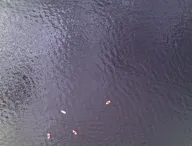
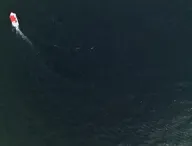
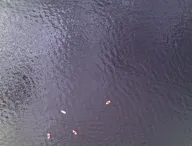
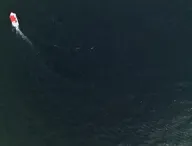

In [6]:
show(result.to_html())

In [7]:
triage = result.steps["factor-triage"].output.data()

In [8]:
latitude = next(f for f in triage["findings"] if f.factor == "latitude")

print("category :", latitude.category)
print("severity :", latitude.severity)
print("reasons  :", latitude.reasons)
print("suggested:", latitude.suggestion.corrections)
print("runnable :", latitude.suggestion.complete)

category : unreadable
severity : blocking
reasons  : ('mixed_types',)
suggested: [{'kind': 'remap', 'factor': 'latitude', 'rules': [{'match': 'N', 'to': None}]}]
runnable : False


In [9]:
print(triage["suggested_policy_yaml"])

metadata:
- name: standard
  corrections:
  - kind: parse_datetime
    factor: date_time
    every: day
  - kind: remap
    factor: latitude
    rules:
    - match: N
      to: null        # TODO
  - kind: remap
    factor: longitude
    rules:
    - match: E
      to: null        # TODO
  - kind: remap
    factor: altitude
    rules:
    - match: -1.0
      to: null        # TODO
  - kind: remap
    factor: compass_heading
    rules:
    - match: -1.0
      to: null        # TODO
  - kind: remap
    factor: gimbal_heading
    rules:
    - match: -1.0
      to: null        # TODO
  - kind: remap
    factor: gimbal_pitch
    rules:
    - match: -1.0
      to: null        # TODO
  - kind: remap
    factor: speed
    rules:
    - match: -1.0
      to: null        # TODO
  exclude:
  - object_id
  continuous_factor_bins:
    frame: 5
    object_size: 12
    xspeed: 2
    yspeed: 2



In [10]:
print(triage["recommended_policy_yaml"])

# Every cut and vocabulary below was read from this data. Pinning them keeps later runs comparable, and it also
# commits them to this data's assumptions. If this data does not represent the data you expect, results computed under
# this policy can be invalid or misleading. Review each factor before you commit it.
metadata:
- name: standard
  corrections:
  - kind: parse_datetime
    factor: date_time
    every: day
  - kind: remap
    factor: latitude
    rules:
    - match: N
      to: .nan  # dropped by default: decide what 'N' means
  - kind: remap
    factor: longitude
    rules:
    - match: E
      to: .nan  # dropped by default: decide what 'E' means
  exclude:
  - object_id
  continuous_factor_bins:
    frame: [-.inf, 2630.75, 5083.5, 7536.25, 9989.0, 12441.75, 14894.5, 17347.25, .inf]  # seen 178 to 19800; the outer bins are open, so values beyond this range join them
    object_size: [-.inf, 42619.625, 85129.25, 127638.875, 170148.5, 212658.125, 255167.75, 297677.375, 340187

In [11]:
from dataeval_flow.config import MetadataPolicyConfig

policy = MetadataPolicyConfig.model_validate(
    {
        "name": "seadrone",
        "corrections": [
            {"kind": "parse_datetime", "factor": "date_time", "every": "day"},
            # Map hemisphere letters to NaN (missing values)
            {"kind": "remap", "factor": "latitude", "rules": [{"match": "N", "to": float("nan")}]},
            {"kind": "remap", "factor": "longitude", "rules": [{"match": "E", "to": float("nan")}]},
            # Map -1.0 sentinel values to NaN
            *(
                {"kind": "remap", "factor": name, "rules": [{"match": -1.0, "to": float("nan")}]}
                for name in ("altitude", "compass_heading", "gimbal_heading", "gimbal_pitch", "speed")
            ),
        ],
        # Exclude object identifier
        "exclude": ["object_id"],
        "continuous_factor_bins": triage["suggested_policy"]["continuous_factor_bins"],
    }
)

corrected = config.model_copy(
    update={
        "metadata": [policy],
        "workflows": [triage_workflow.model_copy(update={"metadata": "seadrone"})],
    }
)
result2 = run_task(corrected, task)
print(f"success={result2.success}  health={result2.health['status']}")

success=True  health=ok


/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_binning.py:418: UserWarning: `altitude`, `compass_heading`, `gimbal_heading`, `gimbal_pitch`, `latitude`, `longitude` and `speed` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"altitude": [...]} to control this.
  factor_info = metadata.factor_info
/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_binning.py:418: UserWarning: Declared cuts left bins unused: frame (4 of 5 bins hold rows), object_size (9 of 12 bins hold rows). The encoding still applies and the codes are unchanged; this is the data no longer matching the policy, not an error. Call reencode() to refit — which moves codes — or leave it and read the empty groups as the finding they are.
  factor_info = metadata.factor_info


In [12]:
after = result2.steps["factor-triage"].output.data()
print(f"factors : {triage['factor_count']} -> {after['factor_count']}")
print(f"findings: {len(triage['findings'])} -> {len(after['findings'])}")
print(f"blocking: {triage['counts'].get('blocking', 0)} -> {after['counts'].get('blocking', 0)}")

factors : 15 -> 17
findings: 24 -> 21
blocking: 3 -> 0


In [13]:
json_str = result.export(fmt="json")
print(f"JSON output: {len(json_str)} characters")

JSON output: 342396 characters
